# Rating-curve comparison — cleaned notebook

Functions and default plot styling are imported from the companion Python module. The original datasets and parameter values are preserved.

In [1]:
# ============================================================
# IMPORTS AND FUNCTION MODULE
# ============================================================

from pathlib import Path
import importlib
import pandas as pd

import rating_curve_DISCHARGE_STAGE_PROBABILITY
import Compare_MODEL_vs_OBSERVED_rating_probability as comparison

import numpy as np

from scipy.interpolate import PchipInterpolator

# ============================================================
# SETTINGS
# ============================================================
importlib.reload(rating_curve_DISCHARGE_STAGE_PROBABILITY)
importlib.reload(comparison)

define_observed_rating_curve = (
    rating_curve_DISCHARGE_STAGE_PROBABILITY.define_observed_rating_curve
)
plot_rating_curve = rating_curve_DISCHARGE_STAGE_PROBABILITY.plot_rating_curve

get_stage_flows = comparison.get_stage_flows
get_gssha_rating_curve = comparison.get_gssha_rating_curve
predict_gssha_probability = comparison.predict_gssha_probability
plot_rating_curve_with_gssha = comparison.plot_rating_curve_with_gssha
calculate_gssha_stage_error = comparison.calculate_gssha_stage_error

PLOT_SETTINGS = comparison.PLOT_SETTINGS.copy()
PLOT_SETTINGS["legend_names"] = comparison.PLOT_SETTINGS["legend_names"].copy()

#PATHS
#SCRIPT
script_dir = Path.cwd()

# Load the rating curve made from previous script (select the specific csv)

In [2]:
# ============================================================
# LOAD SAVED OBSERVED RATING CURVE
# ============================================================

observed_rating_curve_model = pd.read_csv(
    script_dir / "SAVE_DATA" / "OBSERVED-rating-curves-results"
    / "waialua-datum-adjusted_observed_rating_curve_model.csv"
)

display(observed_rating_curve_model)


,Unnamed: 0,stage_ft,lower_cfs,median_cfs,upper_cfs
0,0,12.365117,0.000000,0.000000e+00,7.355188e+01
1,1,12.452840,0.000000,0.000000e+00,7.692485e+01
2,2,12.540562,0.000000,7.324255e-01,8.027346e+01
3,3,12.628285,0.000000,2.279419e+00,8.772115e+01
4,4,12.716007,0.000000,4.359919e+00,9.050303e+01
...,...,...,...,...,...
995,995,99.649110,485529.578816,1.508328e+06,5.037760e+06
996,996,99.736832,485554.781126,1.505525e+06,5.049438e+06
997,997,99.824555,488251.162553,1.531786e+06,5.127500e+06
998,998,99.912277,484235.151719,1.522939e+06,5.167677e+06


### Summarize OBSERVED rating curve by 1 ft increment in stage height

In [3]:
# ============================================================
# DISCHARGE AT 1-FT STAGE INCREMENTS
# ============================================================

observed_stage_flows = get_stage_flows(
    rating_curve_df=observed_rating_curve_model,
    max_stage=35,
    increment=1
)

display(observed_stage_flows)


,stage_ft,flow_cfs,flow_cms
0,13.0,14.016894,0.396914
1,14.0,71.309975,2.019274
2,15.0,156.169032,4.422215
3,16.0,264.843734,7.499539
4,17.0,389.221797,11.021534
5,18.0,527.455211,14.935868
6,19.0,675.606574,19.131048
7,20.0,874.307750,24.757638
8,21.0,1363.976648,38.623518
9,22.0,1925.055895,54.511512


# Load the model results for GSSHA

In [4]:
# ============================================================
# LOAD GSSHA RESULTS — OFFSET-AWARE VERSION
# ============================================================

model_results_dir = script_dir / "model_results" / "Waialua"

gssha_rating_curve, steady_state_WSE, ows_files = get_gssha_rating_curve(
    model_results_dir=model_results_dir,
    tail_records=120,
    offset_m=4.216908,
    increment=1
)
display(gssha_rating_curve)


,flow_cfs,flow_cms,GSSHA_height_m,offset_m,adjusted_height_m,stage_ft,incremental_stage_ft
0,1815,51.395077,2.363093,4.216908,6.580001,21.587931,22
1,2931,82.996677,2.793872,4.216908,7.010780,23.001247,23
2,3959,112.106396,3.088158,4.216908,7.305066,23.966753,24
3,5036,142.603639,3.415456,4.216908,7.632364,25.040563,25
4,6519,184.597523,3.770267,4.216908,7.987175,26.204643,26
5,8084,228.913388,4.072750,4.216908,8.289658,27.197042,27
6,10033,284.102922,4.386365,4.216908,8.603273,28.225960,28
7,12053,341.302952,4.654144,4.216908,8.871052,29.104502,29
8,14744,417.503586,4.957973,4.216908,9.174881,30.101315,30
9,17975,508.995317,5.255755,4.216908,9.472663,31.078291,31


# Assign probability to GSSHA estimated flow

In [5]:
# ============================================================
# ASSIGN PROBABILITIES TO GSSHA SIMULATIONS
# ============================================================
model_results_save = observed_rating_dir = script_dir / "SAVE_DATA" / "OBSERVED-stage-discharge-probability-results"
gssha_rating_curve = predict_gssha_probability(
    gssha_rating_curve=gssha_rating_curve,
    watershed="Waialua",
    probability_dir = model_results_save,
    script_dir=script_dir
)

display(gssha_rating_curve)
gssha_rating_curve.to_csv(script_dir / "SAVE_DATA" / "GSSHA-MODEL_stage-discharge-probability-results" / "Waialua_GSSHA_FIM_results.csv")

Loading probability: Waialua_stage_discharge_probability.csv
Watershed: Waialua
GSSHA simulations: 14
Reference discharge range: 13–44,946 cfs
Models above reference range: 1


,flow_cfs,flow_cms,GSSHA_height_m,offset_m,adjusted_height_m,stage_ft,incremental_stage_ft,EXC_Prob,return_period_years
0,1815,51.395077,2.363093,4.216908,6.580001,21.587931,22,0.590436,1.693665
1,2931,82.996677,2.793872,4.216908,7.010780,23.001247,23,0.397888,2.513268
2,3959,112.106396,3.088158,4.216908,7.305066,23.966753,24,0.284014,3.520955
3,5036,142.603639,3.415456,4.216908,7.632364,25.040563,25,0.204781,4.883272
4,6519,184.597523,3.770267,4.216908,7.987175,26.204643,26,0.135706,7.368885
5,8084,228.913388,4.072750,4.216908,8.289658,27.197042,27,0.091590,10.918243
6,10033,284.102922,4.386365,4.216908,8.603273,28.225960,28,0.058456,17.106991
7,12053,341.302952,4.654144,4.216908,8.871052,29.104502,29,0.038229,26.158043
8,14744,417.503586,4.957973,4.216908,9.174881,30.101315,30,0.022905,43.659290
9,17975,508.995317,5.255755,4.216908,9.472663,31.078291,31,0.013156,76.009936


# Apply observed rating curve model to then plot against the GSSHA output

In [6]:
# ============================================================
# OPTIONAL: FIT OBSERVED RATING CURVE (NUTS — COMPUTATIONALLY EXPENSIVE)
# Run only when you need to refit; otherwise use an existing
# datum_merged_waialua variable already present in your kernel.
# ============================================================

observed_rating_dir = script_dir / "SAVE_DATA" / "OBSERVED-rating-curves-results"

Waialua_adjusted = pd.read_csv(
    observed_rating_dir / "waialua-datum-adjusted_RECOREDED_discharge-stage.csv"
)
Waialua_DATUM_SHIFT_APPLIED = Waialua_adjusted

q = Waialua_DATUM_SHIFT_APPLIED["discharge"].values
h = Waialua_DATUM_SHIFT_APPLIED["stage"].values


datum_merged_waialua = define_observed_rating_curve(
    gauge_height=h,
    discharge=q,
    segments=3,
    dates=None,
    max_discharge=60000,
    uncertainty_bound=95,
    method="nuts"
)

# fig = plot_rating_curve(
#     datum_merged_waialua,
#     title="USGS 16210500 Waialua (adjusted datums) Stage-Discharge Curve",
#     figure_name="Waialua_rating_curve_adjusted_datums.png"
# )


Valid observations: 48
NaNs in stage: 0
NaNs in discharge: 0


Initializing NUTS using jitter+adapt_diag...
C:\Users\bgorberg\anaconda3\envs\ratingcurve_env\Lib\site-packages\pytensor\link\c\cmodule.py:2986: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [b, a, sigma, hs_]


Output()

Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 49 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [a, b, hs_, model_q, sigma]
Sampling: [model_q]


Output()

Sampling: [model_q]


Output()

Rating curve equation
ln(q) = a + sum(b[i] * ln(max(h - hs[i], 0) + ho[i]))
a = 3.6035
b[0] = 1.5218, hs[0] = 12.3429
b[1] = 0.4401, hs[1] = 20.0139
b[2] = 0.4382, hs[2] = 26.2534

ln(q) = 3.6035 + 1.5218 * ln(max(h - 12.3429, 0)) + 0.4401 * ln(max(h - 20.0139, 0) + 1) + 0.4382 * ln(max(h - 26.2534, 0) + 1)


Hodson prediction range: 12.35–100.00 ft
Figure saved to: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\figures\Waialua_rating_curve_comparative_GSSHA.png


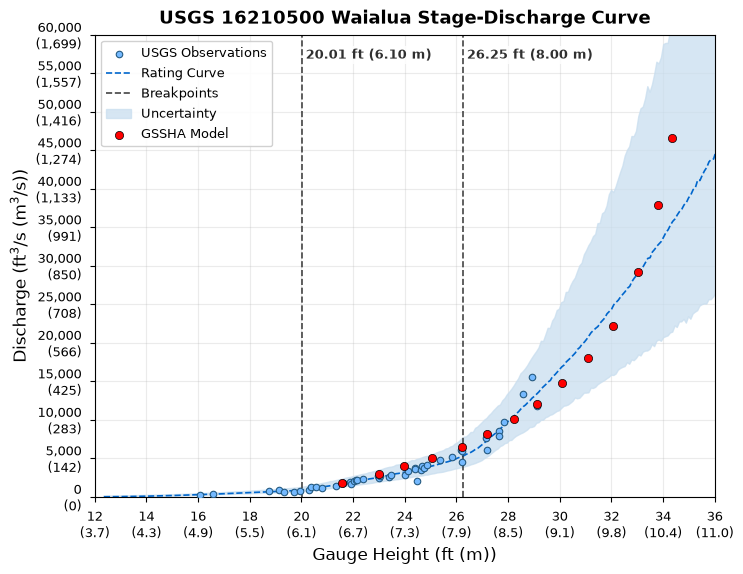

In [7]:
# ============================================================
# COMPARISON FIGURE — EDIT ONLY THESE INPUTS
# Requires datum_merged_waialua from a prior fit or the cell above.
# ============================================================

fig = plot_rating_curve_with_gssha(
    meta=datum_merged_waialua,
    gssha_rating_curve=gssha_rating_curve,
    title="USGS 16210500 Waialua Stage-Discharge Curve",
    figure_name="Waialua_rating_curve_comparative_GSSHA.png",
    output_folder=script_dir / "figures",
    min_stage=12,
    max_stage=36,
    min_discharge=0,
    max_discharge=60000,
    settings=PLOT_SETTINGS
)


# Calculate model uncertainty using the observed rating curve and model results

In [8]:


output_folder = script_dir / "SAVE_DATA" / "GSSHA-MODEL-observed-stage-uncertainty"
output_filename = "Waialua_GSSHA_stage_error.csv"





# ============================================================
# RUN FOR WAIALUA
# ============================================================

gssha_stage_error = calculate_gssha_stage_error(
    gssha_rating_curve=gssha_rating_curve,
    observed_rating_meta=datum_merged_waialua,
    output_folder=output_folder,
    output_filename=output_filename
)

# ============================================================
# DISPLAY RESULTS
# ============================================================

display(
    gssha_stage_error[
        [
            "flow_cfs",
            "stage_ft",
            "observed_stage_ft",
            "stage_error_ft",
            "stage_error_m",
            "absolute_stage_error_ft"
        ]
    ].round(3)
)


GSSHA STAGE ERROR SUMMARY
Total simulations: 14
Valid comparisons: 14
Mean bias: -0.350 ft
Mean absolute error: 0.700 ft
RMSE: 0.862 ft

Saved: C:\Users\bgorberg\Documents\GitHub\Rating_Curve_Probability\SAVE_DATA\GSSHA-MODEL-observed-stage-uncertainty\Waialua_GSSHA_stage_error.csv


,flow_cfs,stage_ft,observed_stage_ft,stage_error_ft,stage_error_m,absolute_stage_error_ft
0,1815,21.588,21.896,-0.308,-0.094,0.308
1,2931,23.001,23.709,-0.708,-0.216,0.708
2,3959,23.967,25.165,-1.198,-0.365,1.198
3,5036,25.041,26.259,-1.218,-0.371,1.218
4,6519,26.205,26.843,-0.638,-0.195,0.638
5,8084,27.197,27.404,-0.207,-0.063,0.207
6,10033,28.226,28.048,0.178,0.054,0.178
7,12053,29.105,28.696,0.408,0.124,0.408
8,14744,30.101,29.506,0.595,0.181,0.595
9,17975,31.078,30.407,0.672,0.205,0.672
